# Pharmaceutical Demand Forecasting & Supply-Chain Planning (v6 — simulation demo + accuracy by planning level)
### Dengue-related pharmacy sales (Jan 2025 – Oct 2026) · XGBoost vs LightGBM

**Pipeline**
1. Load, validate and explore the billing data
2. Aggregate bill lines into a **weekly** demand series (daily data is too sparse)
3. Feature engineering (lags, rolling stats, calendar, monsoon flags)
4. Time-based train/test split, baselines, tuned **XGBoost** and **LightGBM**
5. Forecast **total** demand and **per-medicine** demand (global model)
6. Recursive multi-week forecast
7. **Enriched dataset**: Chennai weather (auto-download), dengue-intensity signals from the bills themselves, Tamil Nadu holidays, and an optional weekly dengue-case file
8. **Fine-tuning**: rolling-origin validation (5 windows), feature-set selection, Optuna search, CV-weighted blend
9. Supply-chain layer: safety stock, reorder point, order-up-to level, EOQ, ABC-XYZ
10. Backtest of the stock policy (service level / fill rate)

> Note: the file contains *sales* (billing lines), which is a proxy for demand. Stock-outs are not recorded, so true demand may be slightly higher.

## 0. Setup

In [1]:
# !pip install xgboost lightgbm   # uncomment on Colab if needed
import os, sys, subprocess, importlib, warnings
warnings.filterwarnings("ignore")
for _pkg in ["optuna", "holidays", "xgboost", "lightgbm"]:      # auto-install missing packages (Colab)
    try: importlib.import_module(_pkg)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
import xgboost as xgb
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
try:
    import holidays
except ImportError:
    holidays = None          # pip install holidays

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 1. Load & validate data

In [2]:
DATA_PATH = "pharmacy_dengue_related_sales_2025_to_2026.csv"

if not os.path.exists(DATA_PATH):
    try:                                    # Google Colab upload fallback
        from google.colab import files
        DATA_PATH = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError("Put the CSV next to this notebook or edit DATA_PATH.")

df = pd.read_csv(DATA_PATH, parse_dates=["Bill_Date"])
print("Shape:", df.shape)
print("Date range:", df.Bill_Date.min().date(), "->", df.Bill_Date.max().date())
display(df.head())

Saving pharmacy_dengue_related_sales_2025_to_2026 (1).csv to pharmacy_dengue_related_sales_2025_to_2026 (1).csv
Shape: (1018, 11)
Date range: 2025-01-02 -> 2026-10-26


,Bill_ID,Bill_Date,Customer_Name,Line_Item_No,Medicine_Name,Category,Quantity,Unit_Price_INR,Line_Total_INR,Reason_for_Purchase,Clinical_Note
0,SM-250102-0001,2025-01-02,Revathi Kannan,1,Paracetamol 500 mg tablets,Fever/pain relief,3,15.0,45.0,Post-consultation supportive-care purchase,Fever/pain relief; use only as directed
1,SM-250102-0001,2025-01-02,Revathi Kannan,2,Electrolyte oral solution,Hydration support,2,30.0,60.0,Post-consultation supportive-care purchase,Hydration support; check product label
2,SM-250102-0002,2025-01-02,Shalini Natarajan,1,Paracetamol oral suspension 120 mg/5 mL,Fever/pain relief,1,42.0,42.0,Dengue supportive care (customer-reported),Pediatric fever relief; dose requires weight/c...
3,SM-250103-0003,2025-01-03,Vijay Anand,1,Paracetamol 500 mg tablets,Fever/pain relief,4,15.0,60.0,Fever/body pain; dengue mentioned by customer,Fever/pain relief; use only as directed
4,SM-250103-0003,2025-01-03,Vijay Anand,2,Multivitamin tablets,Supplement/supportive care,2,45.0,90.0,Fever/body pain; dengue mentioned by customer,Not a dengue-specific treatment or cure


In [3]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")
print("Duplicate rows:", df.duplicated().sum())
print("Line_Total == Qty x Price for all rows:", np.allclose(df.Quantity * df.Unit_Price_INR, df.Line_Total_INR))
print("Unique bills:", df.Bill_ID.nunique(), "| medicines:", df.Medicine_Name.nunique(), "| categories:", df.Category.nunique())
print("Days with at least one sale:", df.Bill_Date.nunique(), "of", (df.Bill_Date.max() - df.Bill_Date.min()).days + 1)

Missing values:
 none
Duplicate rows: 0
Line_Total == Qty x Price for all rows: True
Unique bills: 650 | medicines: 14 | categories: 6
Days with at least one sale: 424 of 663


## 2. Exploratory analysis

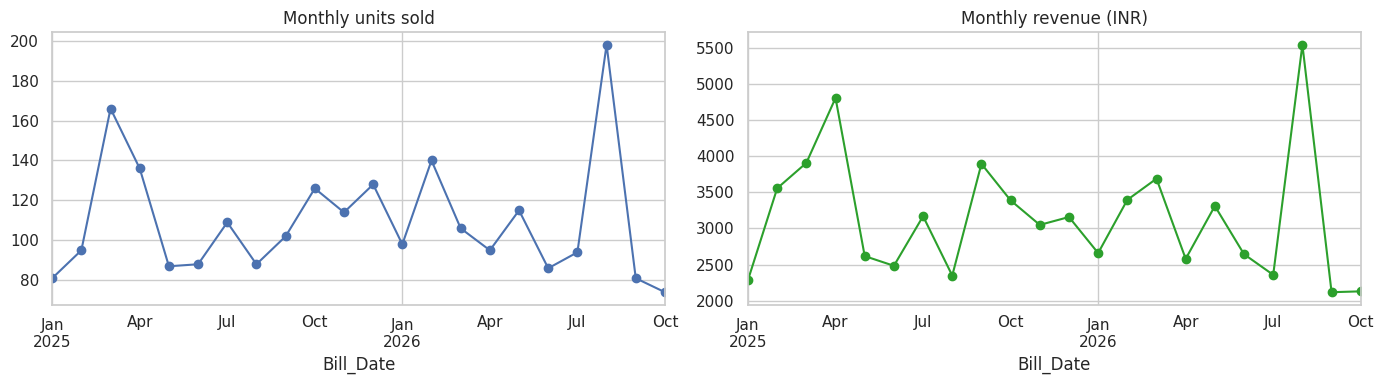

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
m = df.set_index("Bill_Date").resample("MS").agg(units=("Quantity", "sum"), revenue=("Line_Total_INR", "sum"))
m["units"].plot(ax=ax[0], marker="o", title="Monthly units sold")
m["revenue"].plot(ax=ax[1], marker="o", color="tab:green", title="Monthly revenue (INR)")
plt.tight_layout(); plt.show()

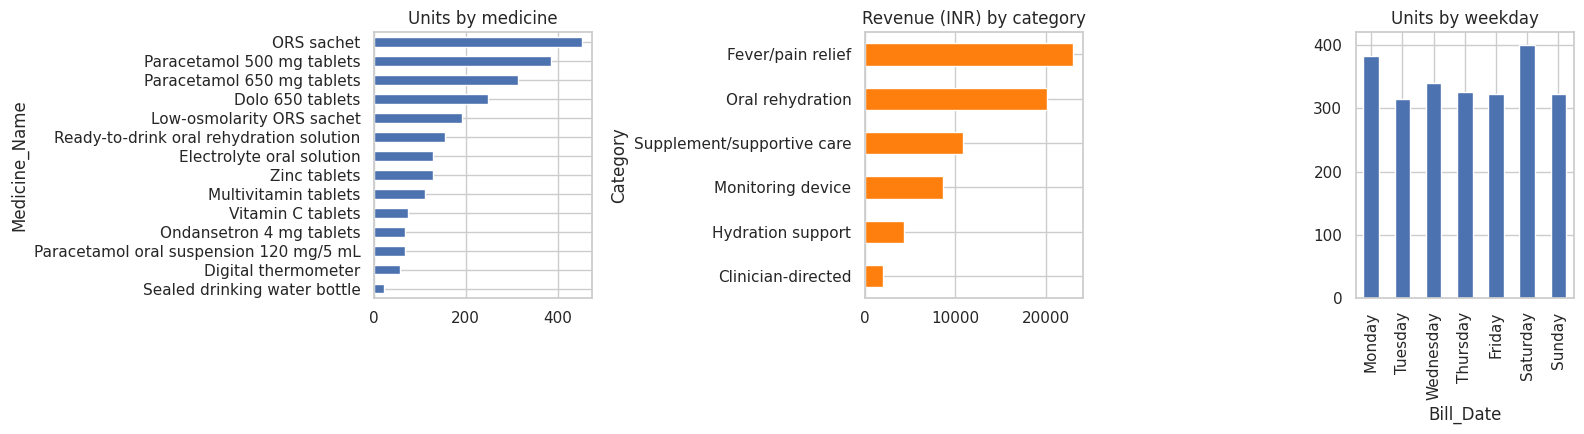

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
df.groupby("Medicine_Name").Quantity.sum().sort_values().plot.barh(ax=ax[0], title="Units by medicine")
df.groupby("Category").Line_Total_INR.sum().sort_values().plot.barh(ax=ax[1], color="tab:orange", title="Revenue (INR) by category")
df.groupby(df.Bill_Date.dt.day_name()).Quantity.sum().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).plot.bar(ax=ax[2], title="Units by weekday")
plt.tight_layout(); plt.show()

## 3. Weekly demand series
Only ~64% of calendar days have a sale and many medicines sell a few times a month, so **weekly** buckets (weeks ending Sunday) are the practical forecasting grain. The final partial week is dropped.

Weeks: 95 | items: 14
Share of zero-demand item-weeks: 0.535


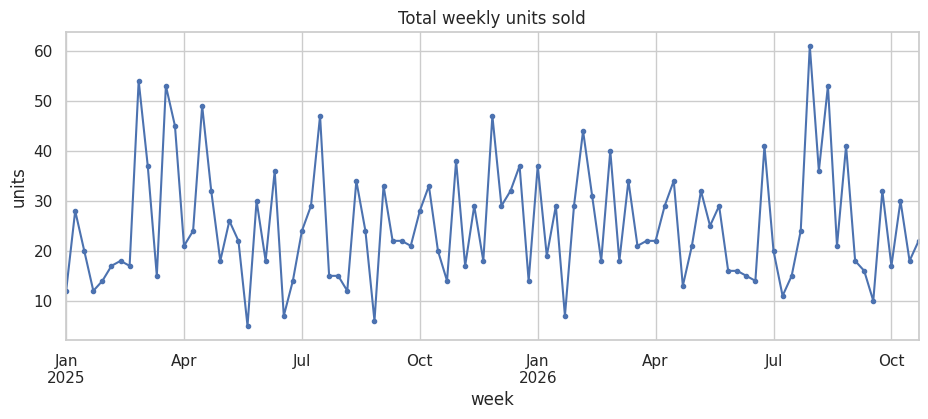

In [6]:
last_date = df.Bill_Date.max()

wide = (df.pivot_table(index="Bill_Date", columns="Medicine_Name", values="Quantity", aggfunc="sum")
          .resample("W-SUN").sum().fillna(0))
wide = wide[wide.index <= last_date]          # drop incomplete trailing week
wide.index.name = "week"; wide.columns.name = "item"

ITEMS = list(wide.columns)
ITEM_CODE = {k: i for i, k in enumerate(ITEMS + ["TOTAL"])}

total = wide.sum(axis=1).rename("qty").reset_index().assign(item="TOTAL")
panel = wide.stack().rename("qty").reset_index()

print("Weeks:", wide.shape[0], "| items:", len(ITEMS))
print("Share of zero-demand item-weeks:", round((panel.qty == 0).mean(), 3))

ax = wide.sum(axis=1).plot(title="Total weekly units sold", marker=".")
ax.set_ylabel("units"); plt.show()

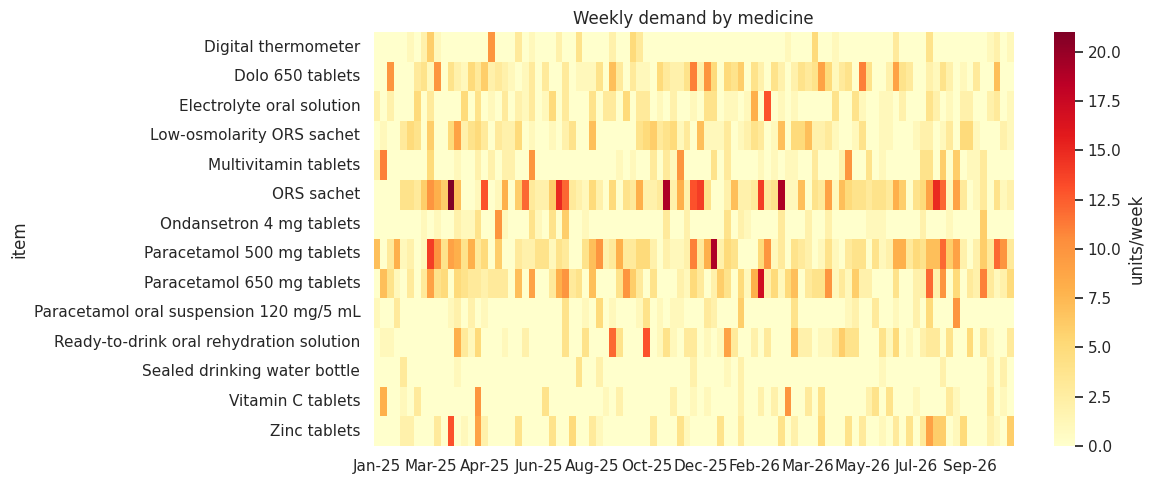

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(wide.T, cmap="YlOrRd", cbar_kws={"label": "units/week"}, ax=ax,
            xticklabels=[d.strftime("%b-%y") if i % 8 == 0 else "" for i, d in enumerate(wide.index)])
ax.set_title("Weekly demand by medicine"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 3a. Weekly dengue case counts (optional but recommended)
Put `chennai_dengue_cases_weekly.csv` next to the notebook (Colab: left panel -> Files -> upload) **or** run the next cell and pick the file.
No real file? Set `SIMULATE_CASES = True` below to run a clearly-labelled **demo** with a synthetic case curve (a seasonal epidemic-style curve that is generated *without looking at your sales*). Every key table then prints a SYNTHETIC warning.
Required columns: a date column (`week_end` = Sunday of the week, or any `date`) and a count column (`dengue_cases`). Daily data is summed to weeks automatically.

In [8]:
ASK_FOR_CASES_FILE = True      # set False to skip the upload prompt
SIMULATE_CASES = False         # True = DEMO ONLY: use a SYNTHETIC dengue curve when no real case file is available
                               # (never use results produced with synthetic cases as a research finding)

def synthetic_warning():
    if globals().get("CASES_ARE_SYNTHETIC"):
        print("*" * 78)
        print("*** SYNTHETIC dengue cases are in use -> these results are a DEMO, not a finding ***")
        print("*" * 78)
CASES_CSV = "chennai_dengue_cases_weekly.csv"
if ASK_FOR_CASES_FILE and not os.path.exists(CASES_CSV):
    try:
        from google.colab import files
        print("Choose chennai_dengue_cases_weekly.csv (Cancel to skip)")
        _up = files.upload()
        if _up:
            os.replace(list(_up.keys())[0], CASES_CSV)
    except ImportError:
        print("Not on Colab: place", CASES_CSV, "next to the notebook to use case counts.")

Choose chennai_dengue_cases_weekly.csv (Cancel to skip)


Saving chennai_dengue_cases_weekly_SYNTHETIC.csv to chennai_dengue_cases_weekly_SYNTHETIC.csv


## 3b. Enriching the dataset
Sales alone cannot explain *why* demand moves. Four extra signal groups are added — all used only as **lagged** values (what was known before the week being forecast):

| Signal | Source | Why it should matter |
|---|---|---|
| Weather (rain, temperature, humidity) | Open-Meteo archive API (free, no key), downloaded once and cached to `chennai_weather_daily.csv` | Rain → stagnant water → *Aedes* breeding → dengue cases ~2–4 weeks later → medicine sales |
| Dengue-intensity from bills | `Reason_for_Purchase` text (bills mentioning dengue / doctor-advised), from your own data | A direct proxy for the local dengue wave, available every week |
| Tamil Nadu public holidays | `holidays` package | Pharmacy footfall changes around holidays/festivals |
| Weekly dengue cases (optional) | `chennai_dengue_cases_weekly.csv` from official bulletins (GCC / TN Directorate of Public Health / IDSP); upload prompt in section 3a | The most direct driver |

For forecasting *future* weeks, unknown weather is filled with the same-week-of-year history (climatology) and unknown internal signals with their last 4-week average. Backtest weeks use observed weather, so the weather gain is slightly optimistic compared with real life (where you would plug in a weather forecast).

In [9]:
USE_EXOG = True                                   # set False to run the pipeline on sales-only features
CITY = {"name": "Chennai", "lat": 13.0827, "lon": 80.2707}
WEATHER_CSV = "chennai_weather_daily.csv"
CASES_CSV   = "chennai_dengue_cases_weekly.csv"   # optional: columns week_end, dengue_cases

H_MAX = 16                                        # weeks of future rows we can create features for
future_idx = pd.date_range(wide.index[-1] + pd.Timedelta(weeks=1), periods=H_MAX, freq="W-SUN")
full_idx = wide.index.append(future_idx); full_idx.name = "week"
n_obs = len(wide.index)

def extend(obs, how):
    # Put a weekly series on full_idx; fill future weeks by climatology or persistence.
    s = obs.reindex(full_idx).astype(float)
    hist = s.iloc[:n_obs].ffill(limit=2)
    s.iloc[:n_obs] = hist.values
    woy_hist = hist.index.isocalendar().week.values
    for k in range(n_obs, len(s)):
        t = s.index[k]
        if how == "climatology":
            m = hist[woy_hist == t.isocalendar()[1]]
            s.iloc[k] = m.mean() if m.notna().any() else hist.mean()
        else:
            s.iloc[k] = hist.dropna().tail(4).mean()
    return s

# ---- 1) weather ---------------------------------------------------------------------------
def fetch_weather(start, end):
    import requests
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params={
        "latitude": CITY["lat"], "longitude": CITY["lon"],
        "start_date": start.strftime("%Y-%m-%d"), "end_date": end.strftime("%Y-%m-%d"),
        "daily": "precipitation_sum,temperature_2m_mean,relative_humidity_2m_mean", "timezone": "Asia/Kolkata"})
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.DataFrame({"date": pd.to_datetime(d["time"]), "rain_mm": d["precipitation_sum"],
                         "temp_c": d["temperature_2m_mean"], "rh_pct": d["relative_humidity_2m_mean"]})

weather = None
if os.path.exists(WEATHER_CSV):
    weather = pd.read_csv(WEATHER_CSV, parse_dates=["date"]); print("Weather loaded from", WEATHER_CSV)
else:
    try:
        end = min(last_date, pd.Timestamp.today().normalize() - pd.Timedelta(days=7))   # archive lags a few days
        weather = fetch_weather(df.Bill_Date.min(), end)
        weather.to_csv(WEATHER_CSV, index=False); print("Weather downloaded:", len(weather), "days")
    except Exception as e:
        print("Weather download failed (", type(e).__name__, ") -> continuing without weather.",
              "Tip: download daily rain/temp/humidity for Chennai into", WEATHER_CSV,
              "with columns date, rain_mm, temp_c, rh_pct.")

sources = {}
if weather is not None:
    wd = weather.set_index("date").sort_index()
    full_weeks = wd.rain_mm.resample("W-SUN").count() == 7          # ignore incomplete weeks
    wk_w = pd.DataFrame({"rain": wd.rain_mm.resample("W-SUN").sum(min_count=1),
                         "temp": wd.temp_c.resample("W-SUN").mean(),
                         "rh":   wd.rh_pct.resample("W-SUN").mean()}).where(full_weeks).reindex(wide.index)
    for c, how in [("rain", "climatology"), ("temp", "climatology"), ("rh", "climatology")]:
        sources[c] = extend(wk_w[c], how)

# ---- 2) dengue-intensity signals from the bills themselves ---------------------------------
b = df.drop_duplicates("Bill_ID").set_index("Bill_Date").sort_index()
b["dengue"] = b.Reason_for_Purchase.str.contains("dengue", case=False).astype(int)
b["doctor"] = b.Reason_for_Purchase.str.contains("doctor-advised", case=False).astype(int)
wk_b = b.resample("W-SUN").agg({"dengue": "sum", "doctor": "sum", "Bill_ID": "count"}).reindex(wide.index).fillna(0)
wk_b["share"] = wk_b.dengue / wk_b.Bill_ID.replace(0, np.nan)
sources["sig_dengue"] = extend(wk_b.dengue, "persist")
sources["sig_doctor"] = extend(wk_b.doctor, "persist")
sources["sig_share"]  = extend(wk_b.share,  "persist")
sources["sig_bills"]  = extend(wk_b.Bill_ID, "persist")

# ---- 3) optional official weekly dengue cases ---------------------------------------------
def load_cases(path):
    # Accepts daily OR weekly data: a date column (week_end/date/week) and a count column (dengue_cases/cases).
    raw = pd.read_csv(path)
    dcol = next((c for c in raw.columns if c.lower() in ("week_end", "date", "week", "week_ending")), None)
    vcol = next((c for c in raw.columns if c.lower() in ("dengue_cases", "cases", "dengue", "count")), None)
    if dcol is None or vcol is None:
        raise ValueError("Need a date column (week_end/date) and a count column (dengue_cases/cases). Found: %s" % list(raw.columns))
    raw[dcol] = pd.to_datetime(raw[dcol], errors="coerce")
    raw[vcol] = pd.to_numeric(raw[vcol], errors="coerce")
    raw = raw.dropna(subset=[dcol]).sort_values(dcol)
    gap = raw[dcol].diff().dt.days.median()
    if gap > 10:
        print("WARNING: dates are %.0f days apart (monthly?). Weekly data is needed - monthly totals would be a poor proxy." % gap)
    return raw.set_index(dcol)[vcol].resample("W-SUN").sum(min_count=1)   # -> weeks ending Sunday

def simulate_cases(index, seed=7):
    # SYNTHETIC weekly cases: low baseline + seasonal peaks (ISO weeks ~39 and ~47) + negative-binomial noise.
    # Generated from the calendar only; it never sees the pharmacy sales.
    rng = np.random.default_rng(seed)
    woy = index.isocalendar().week.values.astype(float)
    mu = 8 + 55 * np.exp(-0.5 * ((woy - 39) / 6) ** 2) + 20 * np.exp(-0.5 * ((woy - 47) / 5) ** 2)
    return pd.Series(rng.negative_binomial(5, 5 / (5 + mu)), index=index).astype(float)

cases_raw = None
CASES_ARE_SYNTHETIC = False
if os.path.exists(CASES_CSV):
    try:
        cases_raw = load_cases(CASES_CSV).reindex(wide.index)
        n_ok = int(cases_raw.notna().sum())
        if n_ok >= 20:
            sources["cases"] = extend(cases_raw, "persist")
            print("Dengue case file used:", n_ok, "of", n_obs, "weeks have counts")
        else:
            print("Dengue case file found but only", n_ok, "weeks match the sales weeks (need >= 20) -> ignored.",
                  "Check that dates are weeks ending on Sunday between", wide.index[0].date(), "and", wide.index[-1].date())
    except Exception as e:
        print("Could not read", CASES_CSV, "->", e)
else:
    print("No", CASES_CSV, "found (optional).")
if "cases" not in sources and SIMULATE_CASES:
    cases_raw = simulate_cases(wide.index)
    sources["cases"] = extend(cases_raw, "persist"); CASES_ARE_SYNTHETIC = True
    print("*** SIMULATION MODE: SYNTHETIC dengue cases generated (not real data) ***")

# ---- 4) holidays --------------------------------------------------------------------------
hol_cnt = pd.Series(0.0, index=full_idx)
if holidays is not None:
    hd = pd.to_datetime(list(holidays.India(subdiv="TN", years=range(2025, 2028)).keys()))
    hol_cnt = pd.Series(1.0, index=hd).sort_index().resample("W-SUN").sum().reindex(full_idx).fillna(0)
else:
    print("`holidays` package missing -> holiday feature set to 0 (pip install holidays).")

# ---- assemble lagged feature table (one row per week) -------------------------------------
exf = pd.DataFrame(index=full_idx)
exf["holiday_cnt"] = hol_cnt
for k, sr in sources.items():
    exf[f"{k}_lag1"]  = sr.shift(1)
    exf[f"{k}_roll4"] = sr.shift(1).rolling(4).mean()
if "rain" in sources:
    for l in (2, 3, 4):
        exf[f"rain_lag{l}"] = sources["rain"].shift(l)
    exf["rain_roll8"] = sources["rain"].shift(1).rolling(8).mean()
EXOG_FEATS = list(exf.columns)
print("Enrichment features:", len(EXOG_FEATS), "->", EXOG_FEATS)

Weather downloaded: 663 days
Dengue case file used: 95 of 95 weeks have counts
Enrichment features: 21 -> ['holiday_cnt', 'rain_lag1', 'rain_roll4', 'temp_lag1', 'temp_roll4', 'rh_lag1', 'rh_roll4', 'sig_dengue_lag1', 'sig_dengue_roll4', 'sig_doctor_lag1', 'sig_doctor_roll4', 'sig_share_lag1', 'sig_share_roll4', 'sig_bills_lag1', 'sig_bills_roll4', 'cases_lag1', 'cases_roll4', 'rain_lag2', 'rain_lag3', 'rain_lag4', 'rain_roll8']


,rain,temp,rh,sig_dengue,sig_doctor,sig_share,sig_bills,cases
signal lagged by N weeks,,,,,,,,
0,-0.04,-0.04,0.06,0.74,0.29,0.03,0.82,-0.07
1,0.10,-0.08,0.14,-0.03,-0.23,0.04,-0.03,0.09
2,0.06,-0.07,-0.01,0.01,0.03,-0.15,0.06,-0.10
3,-0.12,-0.10,0.00,0.03,0.11,0.13,-0.01,-0.02
4,0.05,-0.09,0.05,0.04,-0.09,-0.07,0.05,-0.02
5,0.02,-0.13,0.00,-0.00,0.05,-0.01,-0.03,0.01
6,0.06,-0.20,0.15,-0.16,-0.06,-0.08,-0.12,-0.01


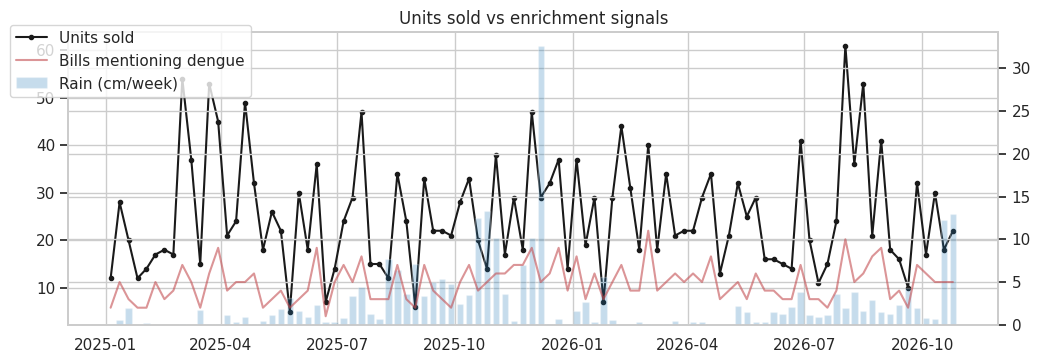

In [10]:
# How does weekly total demand relate to each signal at different lags? (correlation)
y_tot = wide.sum(axis=1)
xc = pd.DataFrame({k: [y_tot.corr(sr.iloc[:n_obs].shift(l)) for l in range(0, 7)] for k, sr in sources.items()},
                  index=pd.Index(range(0, 7), name="signal lagged by N weeks"))
display(xc.round(2))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y_tot.index, y_tot.values, "k.-", label="Units sold")
ax2 = ax.twinx(); ax2.plot(y_tot.index, sources["sig_dengue"].iloc[:n_obs].values, "r-", alpha=.6, label="Bills mentioning dengue")
if "rain" in sources:
    ax2.bar(y_tot.index, sources["rain"].iloc[:n_obs].values / 10, width=5, alpha=.25, color="tab:blue", label="Rain (cm/week)")
ax.set_title("Units sold vs enrichment signals"); fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.92)); plt.show()

### 3c. Dengue case counts vs pharmacy sales
Which lag links official case counts to medicine sales? (Case reports usually *lead* or *coincide* with sales by 0–2 weeks.) This drives the `cases_*` features used in section 6.

Weeks with real counts: 95 of 95 | strongest total-sales correlation at lag 2 weeks (r = -0.10)


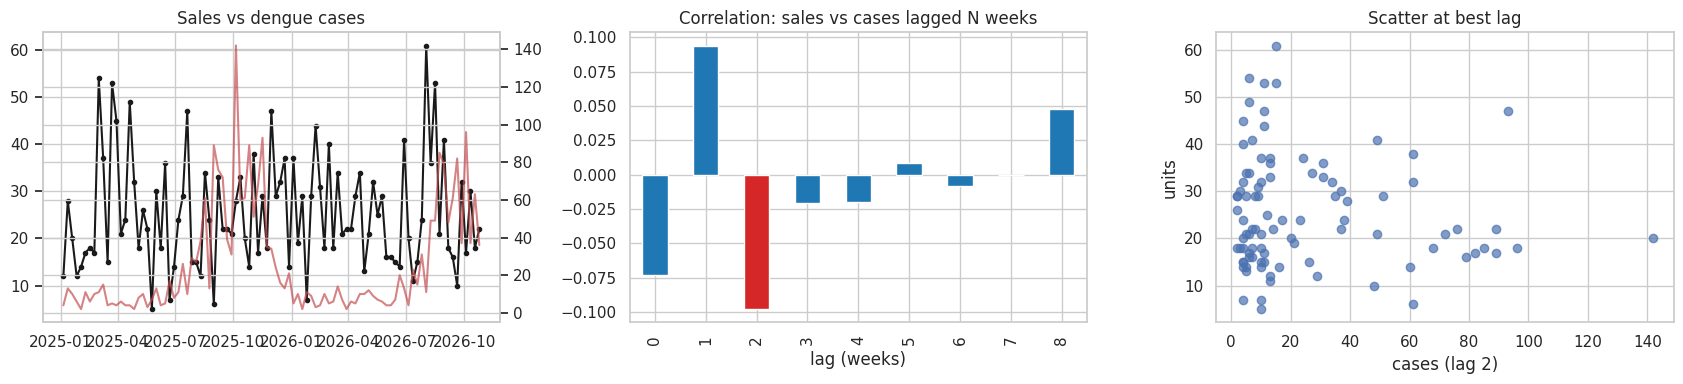

Per-medicine correlation with dengue cases:


,r_at_best_lag,r_same_week
item,,
Sealed drinking water bottle,0.10,0.04
Paracetamol 500 mg tablets,0.08,0.04
Multivitamin tablets,0.05,0.05
Low-osmolarity ORS sachet,0.04,0.02
Ready-to-drink oral rehydration solution,-0.01,0.10
Paracetamol oral suspension 120 mg/5 mL,-0.03,0.05
Zinc tablets,-0.04,-0.03
Electrolyte oral solution,-0.05,-0.01
Vitamin C tablets,-0.06,-0.08


In [11]:
synthetic_warning()
if cases_raw is not None and "cases" in sources:
    cs_w = sources["cases"].iloc[:n_obs]
    lags = list(range(0, 9))
    r_tot = pd.Series([y_tot.corr(cs_w.shift(l)) for l in lags], index=lags)
    best_lag = int(r_tot.abs().idxmax())
    print("Weeks with real counts: %d of %d | strongest total-sales correlation at lag %d weeks (r = %.2f)" % (cases_raw.notna().sum(), n_obs, best_lag, r_tot[best_lag]))

    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(y_tot.index, y_tot.values, "k.-", label="Units sold")
    t2 = ax[0].twinx(); t2.plot(cs_w.index, cs_w.values, "r-", alpha=.7, label="Dengue cases"); ax[0].set_title("Sales vs dengue cases")
    r_tot.plot.bar(ax=ax[1], color=["tab:red" if l == best_lag else "tab:blue" for l in lags]); ax[1].set_title("Correlation: sales vs cases lagged N weeks"); ax[1].set_xlabel("lag (weeks)")
    ax[2].scatter(cs_w.shift(best_lag), y_tot, alpha=.7); ax[2].set_xlabel("cases (lag %d)" % best_lag); ax[2].set_ylabel("units"); ax[2].set_title("Scatter at best lag")
    plt.tight_layout(); plt.show()

    corr_item = pd.DataFrame({"r_at_best_lag": wide.apply(lambda s_: s_.corr(cs_w.shift(best_lag))),
                              "r_same_week": wide.apply(lambda s_: s_.corr(cs_w))}).sort_values("r_at_best_lag", ascending=False)
    print("Per-medicine correlation with dengue cases:")
    display(corr_item.round(2))
else:
    print("No dengue case file loaded -> sections 3c / 6b run without case counts.")

## 4. Feature engineering
Everything is computed from **past** values only (shifted by ≥1 week), so no leakage.

| Feature group | Details |
|---|---|
| Lags | demand 1, 2, 3, 4, 8 weeks ago |
| Rolling | mean (4, 8, 12 wk), median (8 wk), exponential mean, std (4 wk), share of zero weeks (8 wk) |
| Calendar | ISO week, month, sin/cos of week-of-year |
| Season flags | `ne_monsoon` (Oct–Dec) and `sw_monsoon` (Jun–Sep) — Chennai rainy seasons, an assumption you can tune |
| Item | integer code (global model only) |
| Enrichment | lagged weather, dengue-intensity from bills, holiday count, optional case counts (section 3b) |

**Design choices that lowered WAPE** (checked with time-series cross-validation, not on the test set): a smaller feature set for the total series, and MAE-type objectives (`l1`, `huber`) that aim at the *median*, which is what WAPE rewards.

In [12]:
LAGS = [1, 2, 3, 4, 8]

def make_features(p):
    p = p.sort_values(["item", "week"]).copy()
    g = p.groupby("item")["qty"]
    for l in LAGS:
        p[f"lag_{l}"] = g.shift(l)
    p["roll_mean_4"] = g.transform(lambda x: x.shift(1).rolling(4).mean())
    p["roll_mean_8"] = g.transform(lambda x: x.shift(1).rolling(8).mean())
    p["roll_std_4"]  = g.transform(lambda x: x.shift(1).rolling(4).std())
    p["roll_mean_12"] = g.transform(lambda x: x.shift(1).rolling(12).mean())
    p["roll_med_8"]  = g.transform(lambda x: x.shift(1).rolling(8).median())
    p["ewm_3"]       = g.transform(lambda x: x.shift(1).ewm(alpha=0.3).mean())
    p["zero_rate_8"] = g.transform(lambda x: (x.shift(1) == 0).astype(float).rolling(8).mean())
    wk = p["week"].dt.isocalendar().week.astype(int)
    p["week_of_year"] = wk
    p["month"] = p["week"].dt.month
    p["woy_sin"] = np.sin(2 * np.pi * wk / 52)
    p["woy_cos"] = np.cos(2 * np.pi * wk / 52)
    p["ne_monsoon"] = p["month"].isin([10, 11, 12]).astype(int)
    p["sw_monsoon"] = p["month"].isin([6, 7, 8, 9]).astype(int)
    p["item_code"] = p["item"].map(ITEM_CODE)
    p = p.merge(exf.reset_index(), on="week", how="left")       # lagged weather / signals / holidays
    return p.sort_values(["week", "item"]).reset_index(drop=True)

# Total series has only ~90 weeks -> a SMALL feature set generalises better (less over-fitting)
FEATS_TOTAL_BASE = ["lag_1", "roll_mean_4", "roll_mean_8", "ewm_3", "roll_med_8"]
# Per-medicine panel has ~1,200 rows -> can afford a richer set
FEATS = ([f"lag_{l}" for l in LAGS] +
         ["roll_mean_4", "roll_mean_8", "roll_mean_12", "ewm_3", "roll_std_4", "zero_rate_8",
          "week_of_year", "month", "woy_sin", "woy_cos", "ne_monsoon", "sw_monsoon"])
FEATS_PANEL_BASE = FEATS + ["item_code"]

# Enriched variants (sales features + lagged weather / dengue-intensity / holiday signals)
TOTAL_EXOG_PREF = ["rain_roll4", "rain_lag3", "temp_roll4", "rh_roll4", "sig_dengue_lag1", "sig_dengue_roll4",
                   "sig_share_roll4", "cases_lag1", "cases_roll4", "holiday_cnt"]
FEATS_TOTAL_ENR = FEATS_TOTAL_BASE + [c for c in TOTAL_EXOG_PREF if c in EXOG_FEATS]
FEATS_PANEL_ENR = FEATS_PANEL_BASE + EXOG_FEATS
FEATS_TOTAL = FEATS_TOTAL_ENR if USE_EXOG else FEATS_TOTAL_BASE
FEATS_PANEL = FEATS_PANEL_ENR if USE_EXOG else FEATS_PANEL_BASE

total_f = make_features(total).dropna(subset=FEATS_TOTAL_BASE).reset_index(drop=True)
panel_f = make_features(panel).dropna(subset=FEATS).reset_index(drop=True)
print("Total-series rows:", len(total_f), "| Panel rows:", len(panel_f))
display(total_f.tail(3))

Total-series rows: 87 | Panel rows: 1162


,week,qty,item,lag_1,lag_2,lag_3,lag_4,lag_8,roll_mean_4,roll_mean_8,...,sig_share_lag1,sig_share_roll4,sig_bills_lag1,sig_bills_roll4,cases_lag1,cases_roll4,rain_lag2,rain_lag3,rain_lag4,rain_roll8
84,2026-10-11,30.0,TOTAL,17.0,32.0,10.0,16.0,53.0,18.75,26.000,...,0.750000,0.748611,8.0,6.25,96.0,69.00,19.9,43.4,23.3,20.9875
85,2026-10-18,18.0,TOTAL,30.0,17.0,32.0,10.0,21.0,22.25,23.125,...,0.833333,0.756944,6.0,6.50,37.0,63.00,8.1,19.9,43.4,19.9250
86,2026-10-25,22.0,TOTAL,18.0,30.0,17.0,32.0,41.0,24.25,22.750,...,1.000000,0.840278,5.0,7.00,63.0,58.25,7.1,8.1,19.9,31.5750


## 5. Train/test split & metrics
Time-ordered split — the **last 16 weeks** are held out. Metrics: MAE, RMSE, **WAPE** (= Σ|error| / Σ actual, safe for zeros) and bias.

In [13]:
TEST_WEEKS = 16
all_weeks = np.sort(total_f.week.unique())
test_start = all_weeks[-TEST_WEEKS]
print("Train weeks:", (all_weeks < test_start).sum(), "| Test weeks:", TEST_WEEKS, "| test starts", pd.Timestamp(test_start).date())

def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return 100 * np.abs(y - p).sum() / max(y.sum(), 1e-9)

def metrics(y, p, name=""):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"model": name,
            "MAE": np.mean(np.abs(y - p)),
            "RMSE": np.sqrt(np.mean((y - p) ** 2)),
            "WAPE_%": 100 * np.abs(y - p).sum() / max(y.sum(), 1e-9),
            "Bias": np.mean(p - y)}

tr_t, te_t = total_f[total_f.week < test_start], total_f[total_f.week >= test_start]

Train weeks: 71 | Test weeks: 16 | test starts 2026-07-12


## 6. Total weekly demand — baselines, XGBoost, LightGBM

In [14]:
results = [
    metrics(te_t.qty, te_t.lag_1,       "Naive (last week)"),
    metrics(te_t.qty, te_t.roll_mean_4, "Moving avg (4 wk)"),
    metrics(te_t.qty, te_t.roll_mean_8, "Moving avg (8 wk)"),
    metrics(te_t.qty, te_t.ewm_3,       "Exp. smoothing (alpha=0.3)"),
]
tscv = TimeSeriesSplit(n_splits=4)

xgb_space = {"n_estimators": [100, 200, 300, 500], "max_depth": [2, 3, 4, 5],
             "learning_rate": [0.01, 0.03, 0.05, 0.1], "subsample": [0.6, 0.8, 1.0],
             "colsample_bytree": [0.5, 0.7, 1.0], "min_child_weight": [1, 3, 5],
             "reg_lambda": [0.1, 1, 5, 10], "objective": ["reg:squarederror", "reg:absoluteerror", "count:poisson"]}
lgb_space = {"n_estimators": [100, 200, 300, 500], "num_leaves": [4, 8, 15, 31],
             "learning_rate": [0.01, 0.03, 0.05, 0.1], "subsample": [0.6, 0.8, 1.0],
             "colsample_bytree": [0.5, 0.7, 1.0], "min_child_samples": [3, 5, 10],
             "reg_lambda": [0, 1, 5, 10], "objective": ["regression", "l1", "huber", "poisson"]}

def tune(est, space, X, y, n_iter=25, scoring="neg_mean_absolute_error", seed=SEED):
    s = RandomizedSearchCV(est, space, n_iter=n_iter, cv=tscv, scoring=scoring,
                           random_state=seed, n_jobs=-1, refit=True)
    s.fit(X, y); return s

### 6a. Fine-tuning toolkit — rolling-origin validation
A single 16-week test is noisy, so **all choices (feature set, hyper-parameters, blend weights) are made on 5 rolling validation windows of 8 weeks each** taken from the *training* period only. The 16-week test set is touched once, at the end.

In [15]:
N_TRIALS_TOTAL, N_TRIALS_PANEL = 80, 40          # Optuna trials (raise for a deeper search)

def rolling_splits(train, n_folds=5, val_weeks=8, min_train_weeks=26):
    # expanding-window folds; `train` must have a clean 0..n-1 index
    weeks = np.sort(train.week.unique()); n = len(weeks); wk = train.week.values; out = []
    for k in range(n_folds, 0, -1):
        v_end = n - (k - 1) * val_weeks; v_start = v_end - val_weeks
        if v_start < min_train_weeks: continue
        out.append((np.where(wk < weeks[v_start])[0],
                    np.where((wk >= weeks[v_start]) & (wk <= weeks[v_end - 1]))[0]))
    return out

def make_lgb(p): return lgb.LGBMRegressor(random_state=SEED, n_jobs=1, subsample_freq=1, verbose=-1, **p)
def make_xgb(p): return xgb.XGBRegressor(random_state=SEED, n_jobs=1, **p)
MAKERS = {"lgb": make_lgb, "xgb": make_xgb}

def cv_wape(kind, params, train, feats, splits):
    num = den = 0.0
    for tr, va in splits:
        m = MAKERS[kind](params).fit(train.iloc[tr][feats], train.iloc[tr].qty)
        pr = np.clip(m.predict(train.iloc[va][feats]), 0, None)
        num += np.abs(train.iloc[va].qty.values - pr).sum(); den += train.iloc[va].qty.sum()
    return 100 * num / den

def baseline_cv(train, col, splits):
    num = den = 0.0
    for _, va in splits:
        num += np.abs(train.iloc[va].qty.values - train.iloc[va][col].values).sum(); den += train.iloc[va].qty.sum()
    return 100 * num / den

def oof_preds(kind, params, train, feats, splits):
    idx, pr = [], []
    for tr, va in splits:
        m = MAKERS[kind](params).fit(train.iloc[tr][feats], train.iloc[tr].qty)
        idx.append(va); pr.append(np.clip(m.predict(train.iloc[va][feats]), 0, None))
    return np.concatenate(idx), np.concatenate(pr)

DEFAULTS = {"lgb": dict(objective="huber", n_estimators=200, learning_rate=0.03, num_leaves=8, min_child_samples=5,
                        subsample=0.8, colsample_bytree=0.7, reg_lambda=5),
            "xgb": dict(objective="reg:absoluteerror", n_estimators=200, learning_rate=0.03, max_depth=3,
                        min_child_weight=3, subsample=0.8, colsample_bytree=0.7, reg_lambda=5)}

class Tuned:
    # mimics a fitted search object so later sections keep working
    def __init__(self, est, params, cv): self.best_estimator_, self.best_params_, self.best_score_ = est, params, cv

def optuna_tune(kind, train, feats, splits, n_trials=80):
    # Search space is deliberately NARROW (median-type objectives, small trees, strong regularisation):
    # an unrestricted search over-fitted the validation windows on this small dataset.
    def objective(trial):
        if kind == "lgb":
            p = dict(objective=trial.suggest_categorical("objective", ["l1", "huber"]),
                     n_estimators=trial.suggest_int("n_estimators", 50, 300),
                     learning_rate=trial.suggest_float("learning_rate", 0.02, 0.08, log=True),
                     num_leaves=trial.suggest_int("num_leaves", 3, 12),
                     min_child_samples=trial.suggest_int("min_child_samples", 8, 30),
                     subsample=trial.suggest_float("subsample", 0.5, 0.9),
                     colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 0.9),
                     reg_lambda=trial.suggest_float("reg_lambda", 1.0, 20.0))
        else:
            p = dict(objective=trial.suggest_categorical("objective", ["reg:absoluteerror", "reg:squarederror"]),
                     n_estimators=trial.suggest_int("n_estimators", 50, 300),
                     learning_rate=trial.suggest_float("learning_rate", 0.02, 0.08, log=True),
                     max_depth=trial.suggest_int("max_depth", 2, 4),
                     min_child_weight=trial.suggest_int("min_child_weight", 3, 12),
                     subsample=trial.suggest_float("subsample", 0.5, 0.9),
                     colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 0.9),
                     reg_lambda=trial.suggest_float("reg_lambda", 1.0, 20.0))
        return cv_wape(kind, p, train, feats, splits)
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    best = dict(study.best_params)
    return Tuned(MAKERS[kind](best).fit(train[feats], train.qty), best, study.best_value)

trt = tr_t.reset_index(drop=True)
spl_t = rolling_splits(trt)
print("Rolling validation windows:", len(spl_t), "| validation weeks per window: 8 | train rows:", len(trt))

Rolling validation windows: 5 | validation weeks per window: 8 | train rows: 71


### 6b. Which feature set? (chosen by rolling CV, not by the test set)

In [16]:
synthetic_warning()
WEATHER_T = [c for c in ["rain_roll4", "rain_lag2", "rain_lag3", "rain_lag4", "rain_roll8", "temp_roll4", "rh_roll4"] if c in EXOG_FEATS]
cands_t = {"sales only": FEATS_TOTAL_BASE,
           "+ weather": FEATS_TOTAL_BASE + WEATHER_T,
           "+ rain only": FEATS_TOTAL_BASE + [c for c in WEATHER_T if c.startswith("rain")],
           "+ temp/humidity only": FEATS_TOTAL_BASE + [c for c in WEATHER_T if c.startswith(("temp", "rh"))],
           }
if "cases_lag1" in EXOG_FEATS:        # official weekly case counts supplied
    cands_t["+ weather + cases"] = FEATS_TOTAL_BASE + WEATHER_T + [c for c in EXOG_FEATS if c.startswith("cases")]
    cands_t["+ cases only"] = FEATS_TOTAL_BASE + [c for c in EXOG_FEATS if c.startswith("cases")]
rows = []
for nm, fl in cands_t.items():
    sc = [cv_wape(k, DEFAULTS[k], trt, fl, spl_t) for k in ("lgb", "xgb")]
    rows.append({"feature set": nm, "n_features": len(fl), "LGBM CV WAPE %": sc[0], "XGB CV WAPE %": sc[1], "mean": np.mean(sc)})
fs_t = pd.DataFrame(rows).set_index("feature set").sort_values("mean")
display(fs_t.round(2))
BEST_SET_T = fs_t.index[0]
# parsimony rule: keep extra features only if they beat "sales only" by >= 1 CV point (small data -> noisy CV)
if BEST_SET_T != "sales only" and fs_t.loc["sales only", "mean"] - fs_t.loc[BEST_SET_T, "mean"] < 1.0:
    BEST_SET_T = "sales only"
FEATS_TOTAL = cands_t[BEST_SET_T]
print("Chosen feature set for total demand:", BEST_SET_T, "(%d features)" % len(FEATS_TOTAL))
print("Rolling-CV WAPE of baselines -> 4-wk moving avg: %.1f | exp. smoothing: %.1f"
      % (baseline_cv(trt, "roll_mean_4", spl_t), baseline_cv(trt, "ewm_3", spl_t)))

,n_features,LGBM CV WAPE %,XGB CV WAPE %,mean
feature set,,,,
+ temp/humidity only,7,31.94,32.44,32.19
+ weather,12,32.01,33.57,32.79
+ weather + cases,14,32.18,33.43,32.81
+ rain only,10,32.58,37.06,34.82
sales only,5,32.67,37.36,35.02
+ cases only,7,32.89,39.26,36.08


Chosen feature set for total demand: + temp/humidity only (7 features)
Rolling-CV WAPE of baselines -> 4-wk moving avg: 34.2 | exp. smoothing: 34.8


### 6c. Optuna search + CV-weighted blend

In [17]:
lgb_s = optuna_tune("lgb", trt, FEATS_TOTAL, spl_t, N_TRIALS_TOTAL)
xgb_s = optuna_tune("xgb", trt, FEATS_TOTAL, spl_t, N_TRIALS_TOTAL)
print("LGBM best (CV WAPE %.1f):" % lgb_s.best_score_, lgb_s.best_params_)
print("XGB  best (CV WAPE %.1f):" % xgb_s.best_score_, xgb_s.best_params_)

# blend weights from out-of-fold predictions: LightGBM, XGBoost and the exponential-smoothing baseline
i_l, p_l = oof_preds("lgb", lgb_s.best_params_, trt, FEATS_TOTAL, spl_t)
i_x, p_x = oof_preds("xgb", xgb_s.best_params_, trt, FEATS_TOTAL, spl_t)
y_oof, b_oof = trt.qty.values[i_l], trt["ewm_3"].values[i_l]
best_w, best_v = (0.5, 0.5, 0.0), 1e9
for wl in np.arange(0, 1.001, 0.1):
    for wx in np.arange(0, 1.001 - wl, 0.1):
        v = wape(y_oof, wl * p_l + wx * p_x + (1 - wl - wx) * b_oof)
        if v < best_v: best_w, best_v = (wl, wx, 1 - wl - wx), v
print("Blend weights (LGBM, XGB, exp-smoothing): %s -> CV WAPE %.1f" % (tuple(round(w, 1) for w in best_w), best_v))

pred_lgb = np.clip(lgb_s.best_estimator_.predict(te_t[FEATS_TOTAL]), 0, None)
pred_xgb = np.clip(xgb_s.best_estimator_.predict(te_t[FEATS_TOTAL]), 0, None)
pred_blend = best_w[0] * pred_lgb + best_w[1] * pred_xgb + best_w[2] * te_t["ewm_3"].values

results += [metrics(te_t.qty, pred_xgb, "XGBoost (tuned)"),
            metrics(te_t.qty, pred_lgb, "LightGBM (tuned)"),
            metrics(te_t.qty, pred_blend, "Blend (CV-weighted)")]
res_total = pd.DataFrame(results).set_index("model")
cv_map = {"Naive (last week)": baseline_cv(trt, "lag_1", spl_t), "Moving avg (4 wk)": baseline_cv(trt, "roll_mean_4", spl_t),
          "Moving avg (8 wk)": baseline_cv(trt, "roll_mean_8", spl_t), "Exp. smoothing (alpha=0.3)": baseline_cv(trt, "ewm_3", spl_t),
          "XGBoost (tuned)": xgb_s.best_score_, "LightGBM (tuned)": lgb_s.best_score_, "Blend (CV-weighted)": best_v}
res_total["Rolling-CV WAPE %"] = pd.Series(cv_map)
print("Test = last 16 weeks (touched once). Rolling-CV column is optimistic for tuned models (they were tuned on it).")
display(res_total.round(2).sort_values("WAPE_%"))
synthetic_warning()

LGBM best (CV WAPE 31.2): {'objective': 'huber', 'n_estimators': 282, 'learning_rate': 0.07352009701476074, 'num_leaves': 7, 'min_child_samples': 11, 'subsample': 0.8811614039392375, 'colsample_bytree': 0.5815072503666198, 'reg_lambda': 9.567112613394444}
XGB  best (CV WAPE 30.6): {'objective': 'reg:absoluteerror', 'n_estimators': 142, 'learning_rate': 0.02149207048428569, 'max_depth': 2, 'min_child_weight': 4, 'subsample': 0.6717726750030989, 'colsample_bytree': 0.7947947864519528, 'reg_lambda': 1.3839027490856473}
Blend weights (LGBM, XGB, exp-smoothing): (np.float64(0.0), np.float64(1.0), np.float64(0.0)) -> CV WAPE 30.6
Test = last 16 weeks (touched once). Rolling-CV column is optimistic for tuned models (they were tuned on it).


,MAE,RMSE,WAPE_%,Bias,Rolling-CV WAPE %
model,,,,,
Blend (CV-weighted),10.04,14.79,37.80,-3.89,30.65
XGBoost (tuned),10.04,14.79,37.80,-3.89,30.65
LightGBM (tuned),10.24,14.63,38.55,-3.13,31.19
Exp. smoothing (alpha=0.3),12.15,15.30,45.74,0.18,34.79
Moving avg (4 wk),12.30,16.13,46.29,0.42,34.23
Moving avg (8 wk),12.45,16.15,46.88,0.20,33.41
Naive (last week),15.62,18.53,58.82,-0.12,49.71


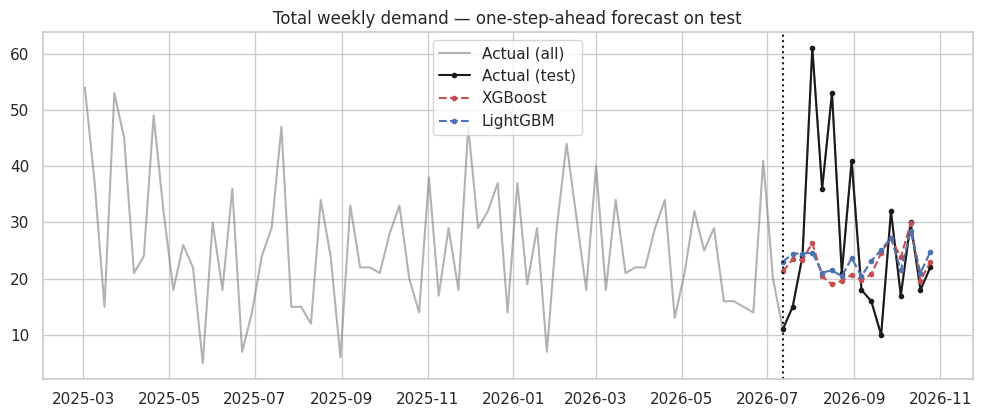

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(total_f.week, total_f.qty, color="grey", alpha=.6, label="Actual (all)")
ax.plot(te_t.week, te_t.qty, "k.-", label="Actual (test)")
ax.plot(te_t.week, pred_xgb, "r--o", ms=3, label="XGBoost")
ax.plot(te_t.week, pred_lgb, "b--o", ms=3, label="LightGBM")
ax.axvline(pd.Timestamp(test_start), ls=":", c="k"); ax.legend(); ax.set_title("Total weekly demand — one-step-ahead forecast on test")
plt.show()

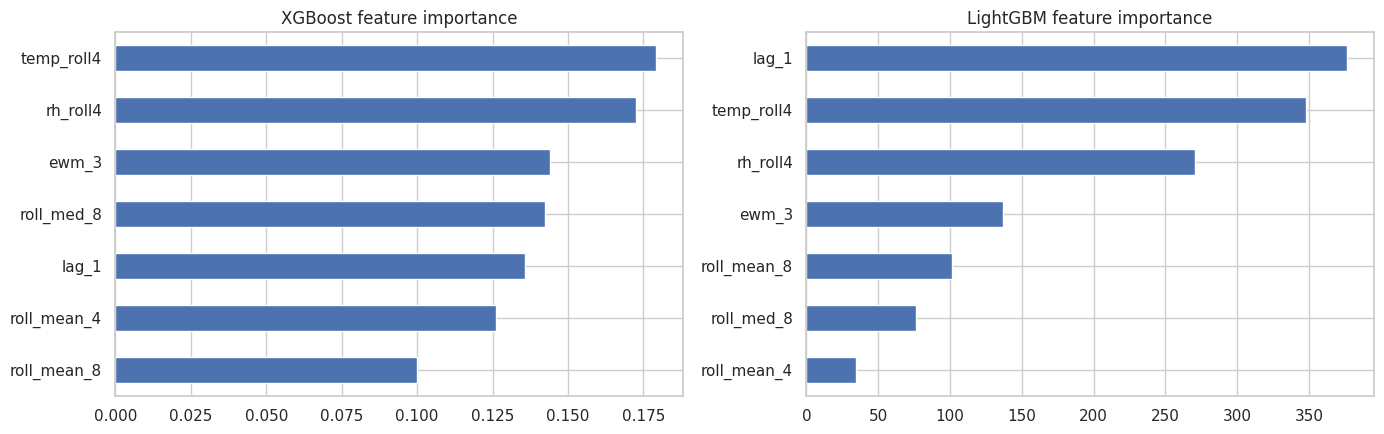

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, mdl, nm in zip(ax, [xgb_s.best_estimator_, lgb_s.best_estimator_], ["XGBoost", "LightGBM"]):
    imp = pd.Series(mdl.booster_.feature_importance("gain") if nm == "LightGBM" else mdl.feature_importances_, index=FEATS_TOTAL)
    imp.sort_values().tail(12).plot.barh(ax=a, title=f"{nm} feature importance")
plt.tight_layout(); plt.show()

### 6b. Honest multi-week check (recursive forecasting)
One-step-ahead scores use *actual* last-week values. In practice you forecast several weeks ahead, feeding predictions back as lags. This is the fairer test for supply planning.

,MAE,RMSE,WAPE_%,Bias
model,,,,
Flat 8-wk mean (16 wk ahead),10.81,15.03,40.71,-4.56
XGBoost recursive (16 wk ahead),10.60,14.85,39.91,-3.99
LightGBM recursive (16 wk ahead),10.84,14.77,40.80,-3.04


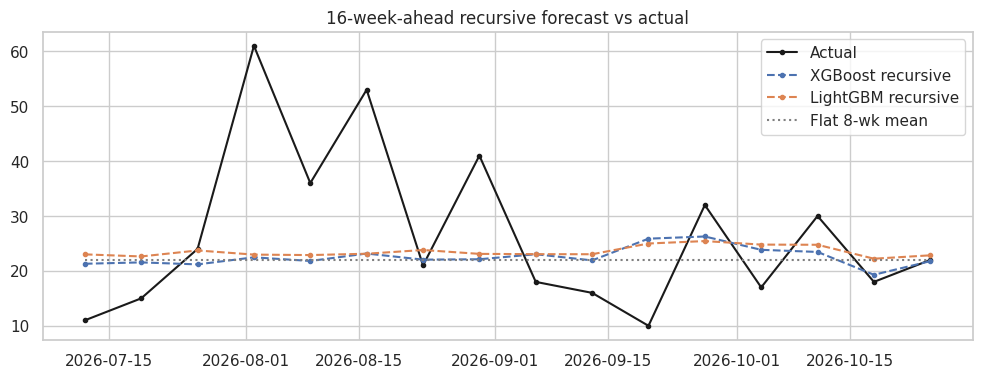

In [20]:
def recursive_forecast(model, hist, horizon, feats):
    """hist: DataFrame[week, item, qty]. Returns DataFrame[week, item, pred] for the next `horizon` weeks."""
    p = hist[["week", "item", "qty"]].copy()
    last_week, items = p.week.max(), p.item.unique()
    for h in range(1, horizon + 1):
        wk = last_week + pd.Timedelta(weeks=h)
        p = pd.concat([p, pd.DataFrame({"week": wk, "item": items, "qty": np.nan})], ignore_index=True)
        f = make_features(p)
        rows = f[f.week == wk]
        pred = np.clip(model.predict(rows[feats]), 0, None)
        p.loc[p.week == wk, "qty"] = p.loc[p.week == wk, "item"].map(dict(zip(rows.item, pred))).values
    return p[p.week > last_week].rename(columns={"qty": "pred"}).reset_index(drop=True)

hist_t = total[total.week < test_start]
rec = {}
for nm, mdl in [("XGBoost", xgb_s.best_estimator_), ("LightGBM", lgb_s.best_estimator_)]:
    rec[nm] = recursive_forecast(mdl, hist_t, TEST_WEEKS, FEATS_TOTAL).pred.values

flat = np.full(TEST_WEEKS, hist_t.qty.tail(8).mean())
rows = [metrics(te_t.qty, flat, "Flat 8-wk mean (16 wk ahead)")]
rows += [metrics(te_t.qty, v, f"{k} recursive (16 wk ahead)") for k, v in rec.items()]
display(pd.DataFrame(rows).set_index("model").round(2))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(te_t.week, te_t.qty.values, "k.-", label="Actual")
for k, v in rec.items(): ax.plot(te_t.week, v, "--o", ms=3, label=k + " recursive")
ax.plot(te_t.week, flat, ":", c="grey", label="Flat 8-wk mean"); ax.legend(); ax.set_title("16-week-ahead recursive forecast vs actual")
plt.show()

### 6d. Accuracy depends on the planning level
A pharmacy orders for a week or a month, not for single noisy weeks. Summing forecasts into **2- and 4-week totals** cancels week-to-week noise, so WAPE drops for *every* method. The comparison with the moving average stays fair because the same blocks are used for all rows. "(1-step)" rows use the actual previous week; the "recursive / 16 wk ahead" rows are the realistic planning case.

In [21]:
y_t = te_t.qty.values
series = {"Moving avg 4 wk (1-step)": te_t.roll_mean_4.values,
          "LightGBM tuned (1-step)": pred_lgb,
          "Blend (1-step)": pred_blend,
          "LightGBM recursive (16 wk ahead)": rec["LightGBM"],
          "Flat 8-wk mean (16 wk ahead)": flat}
rows = {}
for blk in (1, 2, 4):
    n = (len(y_t) // blk) * blk
    ya = y_t[:n].reshape(-1, blk).sum(axis=1)
    rows["%d-week totals" % blk] = {k: wape(ya, np.asarray(v)[:n].reshape(-1, blk).sum(axis=1)) for k, v in series.items()}
print("Total demand - test WAPE % by planning block:")
display(pd.DataFrame(rows).T.round(1))

Total demand - test WAPE % by planning block:


,Moving avg 4 wk (1-step),LightGBM tuned (1-step),Blend (1-step),LightGBM recursive (16 wk ahead),Flat 8-wk mean (16 wk ahead)
1-week totals,46.3,38.5,37.8,40.8,40.7
2-week totals,40.3,35.4,35.5,33.9,33.2
4-week totals,17.4,25.3,26.7,24.7,23.3


## 7. Per-medicine forecasting (global model)
One model is trained on all medicines at once (`item_code` as a feature), which lets sparse items borrow strength from busy ones. This feeds inventory planning.

In [22]:
tr_p, te_p = panel_f[panel_f.week < test_start], panel_f[panel_f.week >= test_start]

synthetic_warning()
trp = tr_p.reset_index(drop=True)
spl_p = rolling_splits(trp)
WEATHER_P = [c for c in EXOG_FEATS if c.startswith(("rain", "temp", "rh"))]
CASES_P = [c for c in EXOG_FEATS if c.startswith("cases")]
cands_p = {"sales only": FEATS_PANEL_BASE,
           "+ weather": FEATS_PANEL_BASE + WEATHER_P}
if CASES_P: cands_p["+ weather + cases"] = FEATS_PANEL_BASE + WEATHER_P + CASES_P
rows = []
for nm, fl in cands_p.items():
    sc = [cv_wape(k, DEFAULTS[k], trp, fl, spl_p) for k in ("lgb", "xgb")]
    rows.append({"feature set": nm, "n_features": len(fl), "LGBM CV WAPE %": sc[0], "XGB CV WAPE %": sc[1], "mean": np.mean(sc)})
fs_p = pd.DataFrame(rows).set_index("feature set").sort_values("mean")
display(fs_p.round(2))
BEST_SET_P = fs_p.index[0]
if BEST_SET_P != "sales only" and fs_p.loc["sales only", "mean"] - fs_p.loc[BEST_SET_P, "mean"] < 1.0:
    BEST_SET_P = "sales only"
FEATS_PANEL = cands_p[BEST_SET_P]
print("Chosen feature set per medicine:", BEST_SET_P, "(%d features)" % len(FEATS_PANEL))

lgb_p = optuna_tune("lgb", trp, FEATS_PANEL, spl_p, N_TRIALS_PANEL)
xgb_p = optuna_tune("xgb", trp, FEATS_PANEL, spl_p, N_TRIALS_PANEL)
print("Rolling-CV WAPE  baseline 4-wk MA: %.1f | LGBM %.1f | XGB %.1f" % (baseline_cv(trp, "roll_mean_4", spl_p), lgb_p.best_score_, xgb_p.best_score_))
print("XGB best :", xgb_p.best_params_)
print("LGBM best:", lgb_p.best_params_)

te_p = te_p.copy()
te_p["xgb"]  = np.clip(xgb_p.best_estimator_.predict(te_p[FEATS_PANEL]), 0, None)
te_p["lgbm"] = np.clip(lgb_p.best_estimator_.predict(te_p[FEATS_PANEL]), 0, None)
te_p["avg"]  = (te_p.xgb + te_p.lgbm) / 2

res_p = pd.DataFrame([
    metrics(te_p.qty, te_p.lag_1, "Naive (last week)"),
    metrics(te_p.qty, te_p.roll_mean_4, "Moving avg (4 wk)"),
    metrics(te_p.qty, te_p.xgb, "XGBoost (global)"),
    metrics(te_p.qty, te_p.lgbm, "LightGBM (global)"),
    metrics(te_p.qty, te_p.avg, "XGB+LGBM average"),
]).set_index("model").round(2)
display(res_p.sort_values("WAPE_%"))

# Bottom-up check: sum of item forecasts vs actual total
bu = te_p.groupby("week")[["qty", "xgb", "lgbm", "avg"]].sum()
print("Bottom-up total WAPE %  ->", {c: round(100 * np.abs(bu.qty - bu[c]).sum() / bu.qty.sum(), 1) for c in ["xgb", "lgbm", "avg"]})

,n_features,LGBM CV WAPE %,XGB CV WAPE %,mean
feature set,,,,
sales only,18,90.22,90.70,90.46
+ weather + cases,30,89.95,91.63,90.79
+ weather,28,90.24,91.84,91.04


Chosen feature set per medicine: sales only (18 features)
Rolling-CV WAPE  baseline 4-wk MA: 100.7 | LGBM 85.9 | XGB 90.1
XGB best : {'objective': 'reg:absoluteerror', 'n_estimators': 297, 'learning_rate': 0.021985499966519422, 'max_depth': 2, 'min_child_weight': 4, 'subsample': 0.5200032632603528, 'colsample_bytree': 0.8393660504116619, 'reg_lambda': 2.5086864497394403}
LGBM best: {'objective': 'l1', 'n_estimators': 195, 'learning_rate': 0.043861652452685355, 'num_leaves': 3, 'min_child_samples': 22, 'subsample': 0.7870112291406104, 'colsample_bytree': 0.7196912640589587, 'reg_lambda': 16.088376580972685}


,MAE,RMSE,WAPE_%,Bias
model,,,,
LightGBM (global),1.64,2.84,86.18,-1.12
XGB+LGBM average,1.66,2.76,87.45,-0.91
XGBoost (global),1.69,2.69,89.19,-0.71
Moving avg (4 wk),1.91,2.79,100.65,0.03
Naive (last week),2.22,3.36,117.18,-0.01


Bottom-up total WAPE %  -> {'xgb': np.float64(44.6), 'lgbm': np.float64(60.4), 'avg': np.float64(51.9)}


In [23]:
# --- A separate MEAN-based model for stock planning ------------------------------------------
# L1/huber models forecast the *median* (great for WAPE) but under-state total volume for sparse
# items. Inventory needs the expected demand, so we also train a Poisson/L2 model for planning.
# Tuned on Poisson deviance (a mean-type score) instead of MAE, so predictions stay unbiased in volume.
plan_space = {**lgb_space, "objective": ["poisson"]}
lgb_plan = tune(lgb.LGBMRegressor(random_state=SEED, n_jobs=1, subsample_freq=1, verbose=-1), plan_space,
                tr_p[FEATS_PANEL], tr_p.qty, n_iter=25, scoring="neg_mean_poisson_deviance")
te_p["plan"] = np.clip(lgb_plan.best_estimator_.predict(te_p[FEATS_PANEL]), 0, None)
print("Total test units  actual:", int(te_p.qty.sum()), "| accuracy model (LGBM):", round(te_p.lgbm.sum()),
      "| planning model:", round(te_p.plan.sum()))
print("WAPE planning model:", round(wape(te_p.qty, te_p.plan), 1), "%  (a bit higher, but unbiased in volume)")

BEST_P = res_p.loc[["XGBoost (global)", "LightGBM (global)", "XGB+LGBM average"], "WAPE_%"].idxmin()
print("Best per-medicine model on test:", BEST_P)

per_item = (te_p.groupby("item").apply(lambda g: pd.Series({
    "test_units": g.qty.sum(),
    "WAPE_naive_%": 100 * np.abs(g.qty - g.lag_1).sum() / max(g.qty.sum(), 1),
    "WAPE_xgb_%":  100 * np.abs(g.qty - g.xgb).sum() / max(g.qty.sum(), 1),
    "WAPE_lgbm_%": 100 * np.abs(g.qty - g.lgbm).sum() / max(g.qty.sum(), 1)}))
    .sort_values("test_units", ascending=False).round(1))
display(per_item)

Total test units  actual: 425 | accuracy model (LGBM): 175 | planning model: 397
WAPE planning model: 97.8 %  (a bit higher, but unbiased in volume)
Best per-medicine model on test: LightGBM (global)


,test_units,WAPE_naive_%,WAPE_xgb_%,WAPE_lgbm_%
item,,,,
Paracetamol 500 mg tablets,91.0,67.0,56.7,60.1
ORS sachet,69.0,95.7,74.7,76.0
Paracetamol 650 mg tablets,60.0,128.3,78.1,80.5
Zinc tablets,43.0,107.0,102.5,105.0
Ready-to-drink oral rehydration solution,25.0,140.0,101.8,107.1
Multivitamin tablets,25.0,152.0,111.2,106.6
Dolo 650 tablets,23.0,156.5,106.0,93.6
Low-osmolarity ORS sachet,23.0,100.0,95.7,100.0
Paracetamol oral suspension 120 mg/5 mL,17.0,200.0,126.4,100.7


WAPE % by aggregation level (item-level model, summed up):


,Naive,Moving avg 4wk,XGBoost,LightGBM,XGB+LGBM
Per medicine (14 series),117.2,100.6,89.2,86.2,87.4
Per category (6 series),81.9,66.8,63.8,68.8,65.5
Total (1 series),58.8,46.3,44.6,60.4,51.9


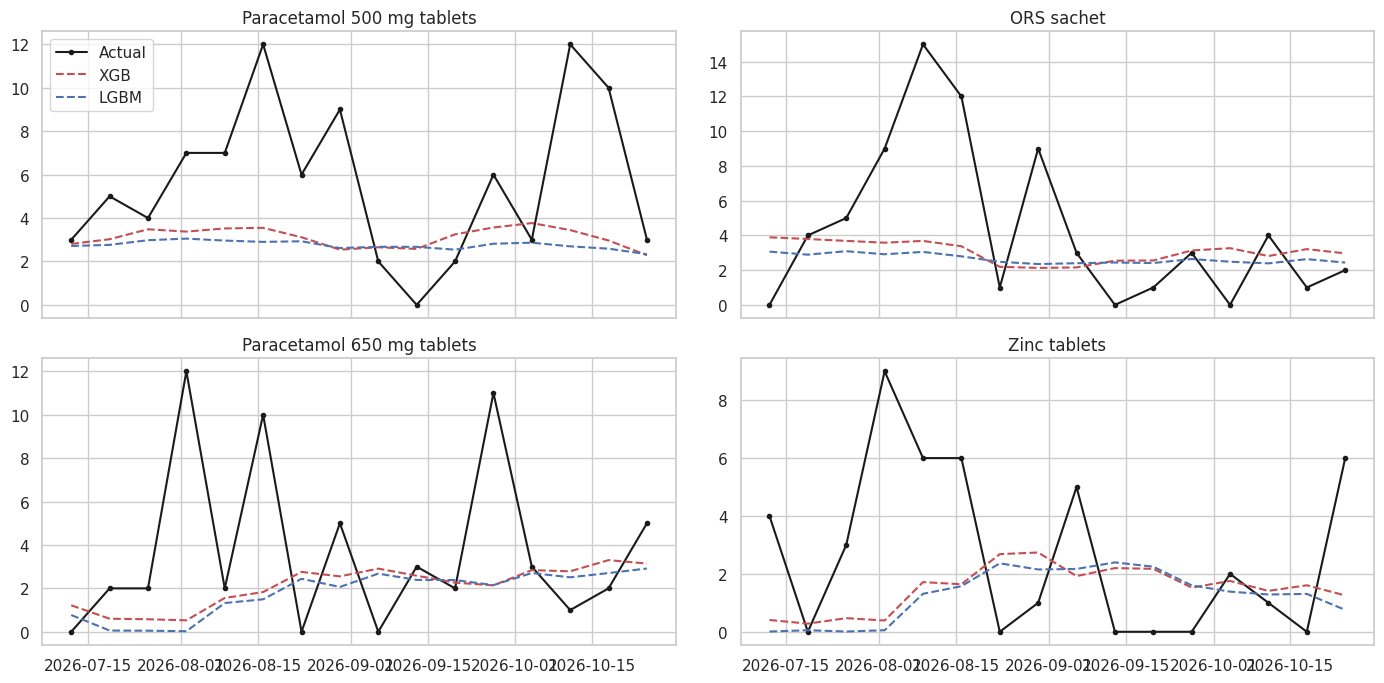

In [24]:
cat_map = df.groupby("Medicine_Name").Category.first()
lvl = {}
for level, key in [("Per medicine (14 series)", None), ("Per category (6 series)", "cat"), ("Total (1 series)", "total")]:
    t = te_p.assign(cat=te_p.item.map(cat_map), total="ALL")
    grp = t if key is None else t.groupby(["week", key])[["qty", "lag_1", "roll_mean_4", "xgb", "lgbm", "avg"]].sum().reset_index()
    lvl[level] = {"Naive": wape(grp.qty, grp.lag_1), "Moving avg 4wk": wape(grp.qty, grp.roll_mean_4),
                  "XGBoost": wape(grp.qty, grp.xgb), "LightGBM": wape(grp.qty, grp.lgbm), "XGB+LGBM": wape(grp.qty, grp.avg)}
print("WAPE % by aggregation level (item-level model, summed up):")
display(pd.DataFrame(lvl).T.round(1))

top = per_item.index[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for a, it in zip(axes.ravel(), top):
    g = te_p[te_p.item == it]
    a.plot(g.week, g.qty, "k.-", label="Actual"); a.plot(g.week, g.xgb, "r--", label="XGB"); a.plot(g.week, g.lgbm, "b--", label="LGBM")
    a.set_title(it)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

### 7b. Does the enriched dataset actually help?
Same search, same test weeks, with and without the new signals. Averaged over 3 different random-search seeds so one lucky draw doesn't decide the answer. **If "+signals" isn't clearly lower, don't claim it helps** — set `USE_EXOG = False`.

In [25]:
def ablate(train, test, feats, seeds=(1, 2, 3), n_iter=15):
    out = {"XGBoost": [], "LightGBM": []}
    for sd in seeds:
        for nm, est, sp in [("XGBoost", xgb.XGBRegressor(random_state=SEED, n_jobs=1), xgb_space),
                            ("LightGBM", lgb.LGBMRegressor(random_state=SEED, n_jobs=1, subsample_freq=1, verbose=-1), lgb_space)]:
            sr = tune(est, sp, train[feats], train.qty, n_iter=n_iter, seed=sd)
            out[nm].append(wape(test.qty, np.clip(sr.predict(test[feats]), 0, None)))
    return {k: np.mean(v) for k, v in out.items()}

rows = []
for lvl, trn, tst, fb, fe in [("Total weekly", tr_t, te_t, FEATS_TOTAL_BASE, FEATS_TOTAL_ENR),
                              ("Per medicine", tr_p, te_p, FEATS_PANEL_BASE, FEATS_PANEL_ENR)]:
    bb, ee = ablate(trn, tst, fb), ablate(trn, tst, fe)
    rows.append({"level": lvl, "XGB sales-only": bb["XGBoost"], "XGB +signals": ee["XGBoost"],
                 "LGBM sales-only": bb["LightGBM"], "LGBM +signals": ee["LightGBM"]})
print("Test WAPE % (mean of 3 search seeds):")
display(pd.DataFrame(rows).set_index("level").round(1))

Test WAPE % (mean of 3 search seeds):


,XGB sales-only,XGB +signals,LGBM sales-only,LGBM +signals
level,,,,
Total weekly,42.9,39.9,43.0,37.9
Per medicine,90.6,92.5,86.9,87.0


### 7c. Direct category-level model
Forecasting the 6 product categories directly (instead of 14 sparse medicines) is usually the best balance for ordering: volumes are larger, so noise matters less. Compared with the bottom-up sum of the medicine-level forecasts.

In [26]:
cat_wide = (df.pivot_table(index="Bill_Date", columns="Category", values="Quantity", aggfunc="sum")
              .resample("W-SUN").sum().fillna(0))
cat_wide = cat_wide[cat_wide.index <= last_date]; cat_wide.index.name = "week"; cat_wide.columns.name = "item"
for c in cat_wide.columns:
    ITEM_CODE.setdefault(c, len(ITEM_CODE))
cat_panel = cat_wide.stack().rename("qty").reset_index()
cat_f = make_features(cat_panel).dropna(subset=FEATS).reset_index(drop=True)
tr_c = cat_f[cat_f.week < test_start].reset_index(drop=True)
te_c = cat_f[cat_f.week >= test_start].copy()

spl_c = rolling_splits(tr_c)
lgb_c = optuna_tune("lgb", tr_c, FEATS_PANEL, spl_c, N_TRIALS_PANEL)
te_c["direct"] = np.clip(lgb_c.best_estimator_.predict(te_c[FEATS_PANEL]), 0, None)

bu = (te_p.assign(item=te_p.item.map(cat_map)).groupby(["week", "item"]).lgbm.sum().rename("bottom_up").reset_index())
te_c = te_c.merge(bu, on=["week", "item"], how="left")
res_cat = pd.DataFrame([
    metrics(te_c.qty, te_c.lag_1, "Naive (last week)"),
    metrics(te_c.qty, te_c.roll_mean_4, "Moving avg (4 wk)"),
    metrics(te_c.qty, te_c.bottom_up, "Bottom-up from medicine model"),
    metrics(te_c.qty, te_c.direct, "LightGBM direct (category)"),
]).set_index("model").round(2)
print("Category level (6 series), test WAPE:")
display(res_cat.sort_values("WAPE_%"))
synthetic_warning()

Category level (6 series), test WAPE:


,MAE,RMSE,WAPE_%,Bias
model,,,,
LightGBM direct (category),2.78,4.67,62.69,-1.08
Moving avg (4 wk),2.96,4.63,66.76,0.07
Bottom-up from medicine model,3.04,5.37,68.76,-2.61
Naive (last week),3.62,5.88,81.88,-0.02


## 8. Final refit & next-8-weeks forecast
The selected models are refit on **all** history and rolled forward recursively.

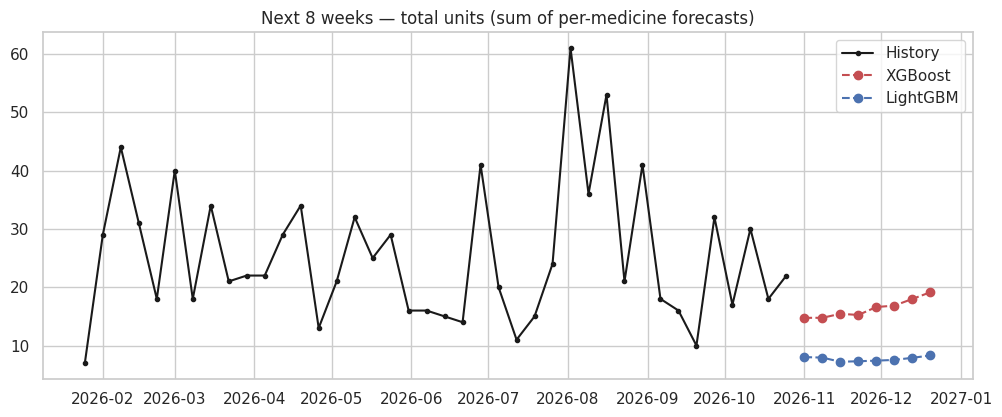

item,Digital thermometer,Dolo 650 tablets,Electrolyte oral solution,Low-osmolarity ORS sachet,Multivitamin tablets,ORS sachet,Ondansetron 4 mg tablets,Paracetamol 500 mg tablets,Paracetamol 650 mg tablets,Paracetamol oral suspension 120 mg/5 mL,Ready-to-drink oral rehydration solution,Sealed drinking water bottle,Vitamin C tablets,Zinc tablets
week,,,,,,,,,,,,,,
2026-11-01,0.0,0.1,0.1,0.1,0.0,1.8,0.0,2.4,2.8,0.0,0.1,0.0,0.0,0.5
2026-11-08,0.0,0.1,0.1,0.1,0.1,1.6,0.0,3.0,2.6,0.0,0.1,0.0,0.0,0.2
2026-11-15,0.1,0.1,0.1,0.1,0.1,1.0,0.0,3.2,2.4,0.0,0.1,0.0,0.0,0.1
2026-11-22,0.1,0.1,0.2,0.1,0.1,1.0,0.1,2.9,2.3,0.0,0.2,0.1,0.0,0.2
2026-11-29,0.2,0.1,0.3,0.2,0.1,0.4,0.1,2.9,2.3,0.1,0.2,0.2,0.0,0.3
2026-12-06,0.2,0.2,0.3,0.3,0.1,0.3,0.1,2.7,2.4,0.1,0.2,0.2,0.0,0.3
2026-12-13,0.2,0.2,0.3,0.3,0.2,0.3,0.2,2.5,2.4,0.2,0.4,0.3,0.0,0.3
2026-12-20,0.3,0.3,0.3,0.3,0.3,0.3,0.3,2.6,2.3,0.3,0.3,0.3,0.0,0.2


In [27]:
HORIZON = 8
full_p = panel_f.copy()
mx = clone(xgb_p.best_estimator_).fit(full_p[FEATS_PANEL], full_p.qty)
ml = clone(lgb_p.best_estimator_).fit(full_p[FEATS_PANEL], full_p.qty)

fc_x = recursive_forecast(mx, panel, HORIZON, FEATS_PANEL).rename(columns={"pred": "xgb"})
fc_l = recursive_forecast(ml, panel, HORIZON, FEATS_PANEL).rename(columns={"pred": "lgbm"})
mp = clone(lgb_plan.best_estimator_).fit(full_p[FEATS_PANEL], full_p.qty)
fc_p = recursive_forecast(mp, panel, HORIZON, FEATS_PANEL).rename(columns={"pred": "plan"})
fc = fc_x.merge(fc_l, on=["week", "item"]).merge(fc_p, on=["week", "item"]); fc["avg"] = (fc.xgb + fc.lgbm) / 2
FC_COL = {"XGBoost (global)": "xgb", "LightGBM (global)": "lgbm", "XGB+LGBM average": "avg"}[BEST_P]

tot_fc = fc.groupby("week")[["xgb", "lgbm", "avg"]].sum()
fig, ax = plt.subplots(figsize=(12, 4.5))
hist_tot = wide.sum(axis=1)
ax.plot(hist_tot.index[-40:], hist_tot.values[-40:], "k.-", label="History")
ax.plot(tot_fc.index, tot_fc.xgb, "r--o", label="XGBoost"); ax.plot(tot_fc.index, tot_fc.lgbm, "b--o", label="LightGBM")
ax.legend(); ax.set_title(f"Next {HORIZON} weeks — total units (sum of per-medicine forecasts)"); plt.show()

display(fc.pivot(index="week", columns="item", values=FC_COL).round(1))

## 9. Supply-chain planning layer
Forecast uncertainty (σ) per medicine is estimated from **out-of-fold, expanding-window residuals** — i.e. errors on data the model hadn't seen — and then turned into inventory parameters.

> ⚠️ Cost, lead-time and service-level values below are **assumptions** — replace them with the pharmacy's real numbers.

In [28]:
# ---- editable assumptions ---------------------------------------------------
SERVICE_LEVEL = 0.95          # target cycle service level
REVIEW_WEEKS  = 1             # how often the pharmacy reviews stock / places orders
DEFAULT_LEAD  = 1             # supplier lead time, weeks
LEAD_TIME = {                 # per-medicine overrides (weeks)
    "Digital thermometer": 2,
    "Ondansetron 4 mg tablets": 2,
}
ORDER_COST = 150              # INR per purchase order
HOLD_RATE  = 0.25             # annual holding cost as a fraction of unit price
Z = norm.ppf(SERVICE_LEVEL)
# -----------------------------------------------------------------------------

def oof_residuals(model, data, feats, n_splits=4):
    data = data.sort_values(["week", "item"]).reset_index(drop=True)
    out = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits).split(data):
        m = clone(model).fit(data.iloc[tr][feats], data.iloc[tr].qty)
        out.append(data.iloc[va].assign(pred=np.clip(m.predict(data.iloc[va][feats]), 0, None)))
    r = pd.concat(out); r["err"] = r.qty - r.pred
    return r

oof = oof_residuals(lgb_plan.best_estimator_, full_p, FEATS_PANEL)
sigma = oof.groupby("item").err.std().reindex(ITEMS).fillna(oof.err.std())
print("OOF residual rows:", len(oof), "| overall residual sd:", round(oof.err.std(), 2))

OOF residual rows: 928 | overall residual sd: 2.78


In [29]:
price = df.groupby("Medicine_Name").Unit_Price_INR.median()
cat   = df.groupby("Medicine_Name").Category.first()
rev   = df.groupby("Medicine_Name").Line_Total_INR.sum()

mu = fc.groupby("item")["plan"].mean().reindex(ITEMS)       # expected weekly demand (mean-based planning model)
L  = pd.Series({i: LEAD_TIME.get(i, DEFAULT_LEAD) for i in ITEMS})
R  = REVIEW_WEEKS

plan = pd.DataFrame({"category": cat, "unit_price": price, "fcst_weekly": mu, "sigma_weekly": sigma, "lead_wk": L}).loc[ITEMS]
plan["safety_stock"]  = Z * plan.sigma_weekly * np.sqrt(plan.lead_wk)
plan["reorder_point"] = plan.fcst_weekly * plan.lead_wk + plan.safety_stock
plan["order_up_to"]   = plan.fcst_weekly * (plan.lead_wk + R) + Z * plan.sigma_weekly * np.sqrt(plan.lead_wk + R)
annual_D = plan.fcst_weekly * 52
H = HOLD_RATE * plan.unit_price
plan["EOQ"] = np.sqrt(2 * annual_D * ORDER_COST / H)

# ABC (revenue) and XYZ (demand variability)
r = rev.reindex(ITEMS).sort_values(ascending=False)
share = r.cumsum() / r.sum()
prev = (share - r / r.sum()).reindex(plan.index)      # cumulative share *before* this item
plan["ABC"] = np.where(prev < 0.80, "A", np.where(prev < 0.95, "B", "C"))
cv = (wide.std() / wide.mean()).reindex(ITEMS)
plan["CV"] = cv
plan["XYZ"] = np.where(cv < 0.5, "X", np.where(cv < 1.0, "Y", "Z"))
plan["segment"] = plan.ABC + plan.XYZ

out = plan.copy()
for c in ["safety_stock", "reorder_point", "order_up_to", "EOQ"]:
    out[c] = np.ceil(out[c])
out[["fcst_weekly", "sigma_weekly", "CV"]] = out[["fcst_weekly", "sigma_weekly", "CV"]].round(2)
display(out.sort_values("fcst_weekly", ascending=False))

,category,unit_price,fcst_weekly,sigma_weekly,lead_wk,safety_stock,reorder_point,order_up_to,EOQ,ABC,CV,XYZ,segment
Paracetamol 500 mg tablets,Fever/pain relief,15.0,4.91,4.36,1,8.0,13.0,20.0,143.0,A,0.90,Y,AY
Paracetamol 650 mg tablets,Fever/pain relief,22.0,4.50,4.18,1,7.0,12.0,19.0,113.0,A,1.01,Z,AZ
ORS sachet,Oral rehydration,22.0,3.70,4.86,1,8.0,12.0,19.0,103.0,A,1.00,Z,AZ
Low-osmolarity ORS sachet,Oral rehydration,25.0,1.79,2.20,1,4.0,6.0,9.0,67.0,A,1.11,Z,AZ
Electrolyte oral solution,Hydration support,30.0,1.60,2.31,1,4.0,6.0,9.0,58.0,A,1.52,Z,AZ
Ready-to-drink oral rehydration solution,Oral rehydration,35.0,1.59,2.93,1,5.0,7.0,10.0,54.0,A,1.57,Z,AZ
Dolo 650 tablets,Fever/pain relief,30.0,1.50,2.86,1,5.0,7.0,10.0,56.0,A,1.07,Z,AZ
Zinc tablets,Supplement/supportive care,25.0,1.42,2.14,1,4.0,5.0,8.0,60.0,B,1.76,Z,BZ
Multivitamin tablets,Supplement/supportive care,45.0,1.34,2.43,1,4.0,6.0,9.0,44.0,A,2.01,Z,AZ
Ondansetron 4 mg tablets,Clinician-directed,30.0,1.33,1.26,2,3.0,6.0,8.0,53.0,C,2.24,Z,CZ


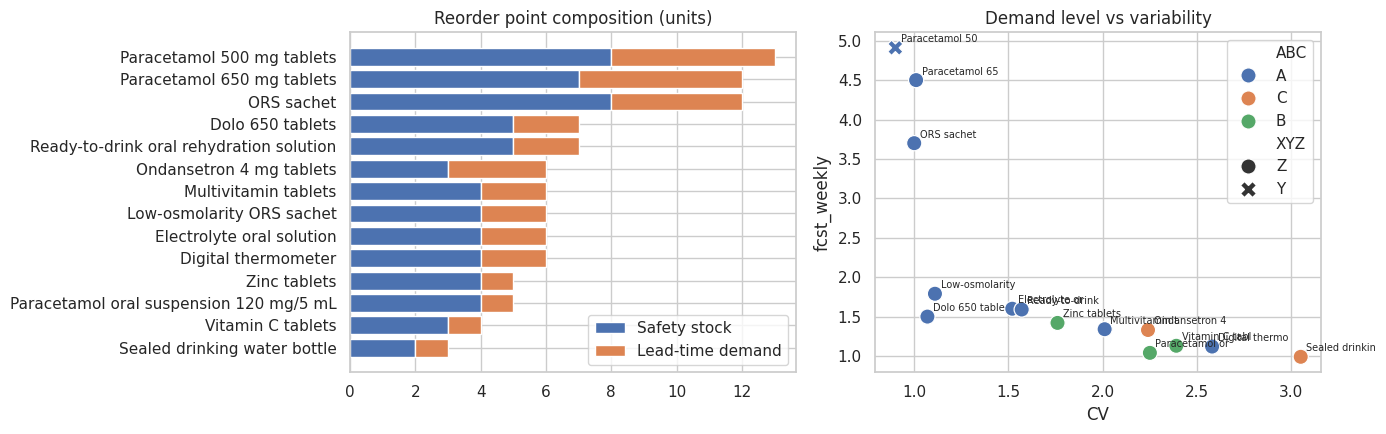

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
o = out.sort_values("reorder_point")
ax[0].barh(o.index, o.safety_stock, label="Safety stock")
ax[0].barh(o.index, o.reorder_point - o.safety_stock, left=o.safety_stock, label="Lead-time demand")
ax[0].set_title("Reorder point composition (units)"); ax[0].legend()
sns.scatterplot(data=out, x="CV", y="fcst_weekly", hue="ABC", style="XYZ", s=120, ax=ax[1])
for i, row in out.iterrows(): ax[1].annotate(i[:14], (row.CV, row.fcst_weekly), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[1].set_title("Demand level vs variability"); plt.tight_layout(); plt.show()

## 10. Backtest of the stock policy
For each test week we stock `forecast + z·σ` (σ estimated from *training-period* out-of-fold errors only) and measure how often demand stays covered.
Compared with the naive 4-week moving average using the same σ logic — the model should deliver a given service level with **less excess stock**.

In [31]:
tr_full = panel_f[panel_f.week < test_start]

def backtest(which):
    if which == "model":
        e = oof_residuals(lgb_plan.best_estimator_, tr_full, FEATS_PANEL)     # sigma from training period only
        pred = te_p["plan"]
    else:
        e = tr_full.assign(err=tr_full.qty - tr_full.roll_mean_4)
        pred = te_p.roll_mean_4
    sg = e.groupby("item").err.std().reindex(ITEMS).fillna(e.err.std())
    upper = pred.values + Z * te_p.item.map(sg).values
    q = te_p.qty.values
    return {"service (weeks covered) %": 100 * np.mean(q <= upper),
            "fill rate %": 100 * (1 - np.maximum(q - upper, 0).sum() / q.sum()),
            "avg excess stock / item-week": np.mean(np.maximum(upper - q, 0)),
            "avg stock held / item-week": upper.mean()}

bt = pd.DataFrame({"Model-based (mean/Poisson LightGBM)": backtest("model"), "Naive 4-wk moving average": backtest("naive")}).T.round(2)
print(f"Target cycle service level: {SERVICE_LEVEL:.0%}")
display(bt)

Target cycle service level: 95%


,service (weeks covered) %,fill rate %,avg excess stock / item-week,avg stock held / item-week
Model-based (mean/Poisson LightGBM),89.29,89.90,3.99,5.69
Naive 4-wk moving average,92.86,92.33,4.55,6.30


## 11. Conclusions & how to extend
**Where accuracy is good (v6)**: report WAPE together with the level it refers to — total demand and 4-week totals have far lower error than single medicines in a single week. §6d and §7c show this transparently.

**What to report** (v4)
- Internal bill-signals and holidays were *not* offered to the model: they showed no predictive value (lag-correlation table, §7b). Weather (and official case counts, if you add them) are the only extra candidates.
- All tuning decisions use rolling-origin CV on the training period; the 16-week test is a one-shot check. Quote both numbers.
- Compare 'sales only' vs '+ weather' in the feature-set tables (§6b and §7) — they show whether weather really helps.
- Compare the tables in §6 and §7: tree models are only worth it where they beat the naive / moving-average baselines on **WAPE**; with ~90 weeks of data the margin can be small, so state this honestly.
- **WAPE depends on the level you forecast**: it is lowest for the total, higher per category and highest per medicine (most medicines sell 0–5 units a week, so noise dominates). The aggregation table in §7 shows this — report it.
- **Accuracy model vs planning model**: L1/huber models minimise WAPE but forecast the median; stock planning uses a separate mean-based (Poisson) model so volume is not under-stated.
- LightGBM vs XGBoost: compare WAPE, bias and runtime; the average of the two is often the most stable.
- §9 converts forecasts into actionable numbers: reorder point, order-up-to level, EOQ, and ABC-XYZ policy classes (A-X: tight control, C-Z: carry minimal stock / order on demand).

**Limitations**
- Sales ≠ demand (stock-outs are invisible); only ~1.8 years of data, so yearly seasonality can't be validated.
- Lead times, order and holding costs in §9 are assumptions.

**Next steps**
1. Fill `chennai_dengue_cases_weekly.csv` from official bulletins (GCC / TN Directorate of Public Health / IDSP) and re-run — case counts are the most direct driver. Report §7b honestly: keep the signals only if they lower WAPE.
2. Add real stock-on-hand and supplier lead-time data to simulate full inventory trajectories.
3. Prediction intervals via quantile objectives (`objective="quantile"` in LightGBM) or conformal prediction.
4. Compare with SARIMAX / Prophet, and try hyper-parameter search with Optuna.
5. Use SHAP for explainability of individual forecasts.